# Notebook 05 — Evaluation, Ablation, 4-Fold Stability, DM', CQR, TreeSHAP & Paper 2024 Benchmark

**Đánh giá toàn diện Luồng Thống nhất `01 → 05`:**
1. Chấm điểm toàn bộ **12 hệ mô hình** (gồm `AutoRouted_Champion`, `Ridge_F1F2F3`, `LightGBM_AnchorRes_F3`, `Hybrid` OOF cải tiến, `Croston_SBA`, `SNaïve Weighted`) trên Hold-out 52W + độ nhạy **51W vs 52W**.
2. **Ablation `F1 → F1+F2 → F1+F2+F3_Compact → LagOnly`** & `Hybrid` (kèm `α*`).
3. **Ổn định 4-Fold Rolling-Origin (`13W/fold` × 4 mùa)** & **Kiểm định Harvey–Diebold–Mariano (`DM'`)** (`52W` & `Daily 365D`).
4. **CQR Global Quantile Coverage (`P10–P90`)**, **Exact TreeSHAP**, và **Đối sánh 2 Tầng với Paper 2024**.

In [1]:
import json
import warnings
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

warnings.filterwarnings("ignore")

from pathlib import Path
import os

def resolve_art_dir() -> Path:
    cwd = Path.cwd().resolve()
    for p in [cwd, *cwd.parents]:
        if (p / "BTL_BI").is_dir():
            d = p / "BTL_BI" / "artifacts" / "forecasting"
            d.mkdir(parents=True, exist_ok=True)
            return d
        if p.name == "BTL_BI":
            d = p / "artifacts" / "forecasting"
            d.mkdir(parents=True, exist_ok=True)
            return d
    d = cwd / "artifacts" / "forecasting"
    d.mkdir(parents=True, exist_ok=True)
    return d

ART_DIR = resolve_art_dir()
print("Artifacts dir:", ART_DIR)

df_feat = pd.read_parquet(ART_DIR / "feature_store_weekly.parquet")
df_daily_feat = pd.read_parquet(ART_DIR / "feature_store_daily.parquet")
df_holdout = pd.read_parquet(ART_DIR / "predictions_holdout_52w.parquet")
df_rolling = pd.read_parquet(ART_DIR / "predictions_rolling_4folds.parquet")
df_quant = pd.read_parquet(ART_DIR / "predictions_quantiles_52w.parquet")
df_daily_pred = pd.read_parquet(ART_DIR / "predictions_daily_365d.parquet")
df_shap = pd.read_parquet(ART_DIR / "shap_values_52w.parquet")
train_summary = json.loads((ART_DIR / "training_summary.json").read_text(encoding="utf-8"))
catalog = json.loads((ART_DIR / "feature_catalog.json").read_text(encoding="utf-8"))

mase_denoms = {}
for atc, g in df_feat.groupby("atc_code"):
    y = g.sort_values("week_idx")["qty"].to_numpy()
    mase_denoms[atc] = float(np.mean(np.abs(y[52:250] - y[:198])))

daily_mase_denoms = {}
for atc, g in df_daily_feat.groupby("atc_code"):
    y = g.sort_values("day_idx")["qty"].to_numpy()
    daily_mase_denoms[atc] = float(np.mean(np.abs(y[7:1741] - y[:1734])))

print("Loaded predictions:", len(df_holdout), "holdout,", len(df_rolling), "rolling,", len(df_daily_pred), "daily,", len(df_quant), "quantile")

Artifacts dir: D:\DOWNLOAD\01_Workspace\DACN\BTL_BI\artifacts\forecasting
Loaded predictions: 4992 holdout, 4576 rolling, 8760 daily, 416 quantile


In [2]:
def score_group(df_g: pd.DataFrame, mase_denom: float) -> pd.Series:
    yt = df_g["y_true"].to_numpy()
    yp = df_g["y_pred"].to_numpy()
    err = yp - yt
    mae = float(np.mean(np.abs(err)))
    mse = float(np.mean(err ** 2))
    rmse = float(np.sqrt(mse))
    tot = float(np.sum(yt))
    wape = 100.0 * float(np.sum(np.abs(err))) / tot if tot > 0 else np.nan
    bias = 100.0 * float(np.sum(err)) / tot if tot > 0 else np.nan
    with np.errstate(divide="ignore", invalid="ignore"):
        ape = np.where(yt == 0, np.where(yp == 0, 0.0, np.inf), np.abs(err) / yt)
    mape = 100.0 * float(np.mean(ape))
    return pd.Series({
        "MSE": round(mse, 2), "RMSE": round(rmse, 2), "MAE": round(mae, 2),
        "WAPE_pct": round(wape, 2), "MASE": round(mae / mase_denom, 3),
        "Bias_pct": round(bias, 2), "MAPE_pct": np.inf if np.isinf(mape) else round(mape, 2),
    })

rows = []
for (atc, model), g in df_holdout.groupby(["atc_code", "model_name"]):
    s = score_group(g, mase_denoms[atc])
    s["fold_id"], s["atc_code"], s["model_name"] = "holdout_52w", atc, model
    s["feature_set"] = g["feature_set"].iloc[0]
    rows.append(s)

df_metrics = pd.DataFrame(rows)[["fold_id", "atc_code", "model_name", "feature_set", "MSE", "RMSE", "MAE", "WAPE_pct", "MASE", "Bias_pct", "MAPE_pct"]]
df_metrics.to_csv(ART_DIR / "metrics_by_atc.csv", index=False)

print("=== UNIFIED WAPE (%) BY ATC (52-WEEK HOLD-OUT) ===")
display(df_metrics.pivot(index="atc_code", columns="model_name", values="WAPE_pct").round(2))
print("\n=== UNIFIED MSE BY ATC (52-WEEK HOLD-OUT) ===")
display(df_metrics.pivot(index="atc_code", columns="model_name", values="MSE").round(2))

winners_oracle = df_metrics.sort_values(["atc_code", "MSE"]).groupby("atc_code").first().reset_index()
winners_wape = df_metrics.sort_values(["atc_code", "WAPE_pct"]).groupby("atc_code").first().reset_index()
routed_df = df_metrics[df_metrics["model_name"] == "AutoRouted_Champion"].sort_values("atc_code").reset_index(drop=True)
print("\n=== ZERO-LEAKAGE AUTOROUTED CHAMPION (Selected Strictly by Val MAE) ===")
display(routed_df[["atc_code", "feature_set", "WAPE_pct", "MASE", "MSE", "Bias_pct"]])
print("\n=== LOWEST MSE BY ATC (Post-hoc) ===")
display(winners_oracle[["atc_code", "model_name", "MSE", "WAPE_pct", "MASE", "Bias_pct"]])

sens_rows = []
for (atc, model), g52 in df_holdout.groupby(["atc_code", "model_name"]):
    g51 = g52[g52["week_idx"] < 301]
    s52 = score_group(g52, mase_denoms[atc])
    s51 = score_group(g51, mase_denoms[atc])
    sens_rows.append({
        "atc_code": atc, "model_name": model,
        "MSE_52W": s52["MSE"], "MSE_51W": s51["MSE"],
        "WAPE_52W": s52["WAPE_pct"], "WAPE_51W": s51["WAPE_pct"],
        "Delta_MSE_partial_wk": round(float(s52["MSE"] - s51["MSE"]), 2),
    })
df_sens = pd.DataFrame(sens_rows)
df_sens.to_csv(ART_DIR / "sensitivity_51w_vs_52w.csv", index=False)

=== UNIFIED WAPE (%) BY ATC (52-WEEK HOLD-OUT) ===


model_name,AutoRouted_Champion,Croston_SBA,Harmonic_ARIMA,Hybrid_SARIMA_LGBM_F3,LightGBM_AnchorRes_F3,LightGBM_F1,LightGBM_F1F2,LightGBM_F1F2F3,LightGBM_F1F2F3_LagOnly,Ridge_F1F2F3,Seasonal_Naive,Seasonal_Naive_Weighted
atc_code,,,,,,,,,,,,
M01AB,15.74,15.74,15.47,15.88,16.17,15.22,16.64,16.83,16.26,15.03,22.96,18.51
M01AE,25.17,26.78,24.97,24.97,25.13,26.91,26.10,25.96,26.42,25.17,29.42,28.18
N02BA,20.92,19.92,20.92,20.92,20.25,20.15,20.67,22.06,22.55,21.34,27.57,33.11
N02BE,15.44,21.26,15.83,15.83,12.96,16.54,15.38,15.44,13.94,14.36,21.83,15.27
N05B,16.49,16.57,17.94,17.94,16.49,17.30,17.52,16.76,16.32,15.55,28.04,20.27
N05C,47.94,44.24,47.22,47.22,46.50,46.87,48.44,47.94,46.74,48.31,69.62,54.13
R03,38.32,36.71,37.56,38.83,38.32,39.68,38.49,38.46,38.86,36.46,49.34,46.80
R06,24.67,28.75,25.01,25.12,24.67,27.22,23.26,26.84,27.35,24.84,36.75,27.56



=== UNIFIED MSE BY ATC (52-WEEK HOLD-OUT) ===


model_name,AutoRouted_Champion,Croston_SBA,Harmonic_ARIMA,Hybrid_SARIMA_LGBM_F3,LightGBM_AnchorRes_F3,LightGBM_F1,LightGBM_F1F2,LightGBM_F1F2F3,LightGBM_F1F2F3_LagOnly,Ridge_F1F2F3,Seasonal_Naive,Seasonal_Naive_Weighted
atc_code,,,,,,,,,,,,
M01AB,58.24,58.24,58.35,61.63,61.60,54.38,63.63,62.18,61.08,52.68,107.08,72.49
M01AE,72.64,86.03,69.46,69.46,67.56,89.29,85.89,84.42,85.92,72.64,105.88,86.98
N02BA,29.06,28.89,29.06,29.06,29.21,28.31,27.72,32.70,34.80,32.35,52.07,75.57
N02BE,2042.84,4014.57,1841.96,1841.96,1392.20,2111.92,1983.25,2042.84,1697.91,1718.77,3605.15,2404.25
N05B,139.66,126.26,152.58,152.58,139.66,147.45,144.77,130.48,125.47,118.65,450.79,239.42
N05C,8.66,7.76,8.40,8.40,7.99,8.57,9.02,8.66,8.27,8.81,21.75,10.95
R03,688.80,721.19,662.25,674.88,688.80,886.72,866.52,889.54,918.57,768.06,1142.61,1087.25
R06,57.04,95.65,64.18,58.51,57.04,61.95,49.75,63.64,65.78,61.43,137.75,86.50



=== ZERO-LEAKAGE AUTOROUTED CHAMPION (Selected Strictly by Val MAE) ===


,atc_code,feature_set,WAPE_pct,MASE,MSE,Bias_pct
0,M01AB,selected=Croston_SBA|valMAE=5.72,15.74,0.614,58.24,-6.35
1,M01AE,selected=Ridge_F1F2F3|valMAE=4.78,25.17,0.993,72.64,2.27
2,N02BA,selected=Harmonic_ARIMA|valMAE=3.72,20.92,0.623,29.06,-0.78
3,N02BE,selected=LightGBM_F1F2F3|valMAE=26.81,15.44,0.523,2042.84,-1.59
4,N05B,selected=LightGBM_AnchorRes_F3|valMAE=11.02,16.49,0.365,139.66,-2.20
5,N05C,selected=LightGBM_F1F2F3|valMAE=2.84,47.94,0.720,8.66,-25.60
6,R03,selected=LightGBM_AnchorRes_F3|valMAE=12.60,38.32,1.182,688.80,-0.83
7,R06,selected=LightGBM_AnchorRes_F3|valMAE=5.52,24.67,0.830,57.04,-0.64



=== LOWEST MSE BY ATC (Post-hoc) ===


,atc_code,model_name,MSE,WAPE_pct,MASE,Bias_pct
0,M01AB,Ridge_F1F2F3,52.68,15.03,0.587,-3.23
1,M01AE,LightGBM_AnchorRes_F3,67.56,25.13,0.991,3.57
2,N02BA,LightGBM_F1F2,27.72,20.67,0.615,1.89
3,N02BE,LightGBM_AnchorRes_F3,1392.20,12.96,0.439,-1.47
4,N05B,Ridge_F1F2F3,118.65,15.55,0.344,-2.29
5,N05C,Croston_SBA,7.76,44.24,0.665,-10.54
6,R03,Harmonic_ARIMA,662.25,37.56,1.159,-0.12
7,R06,LightGBM_F1F2,49.75,23.26,0.783,-0.20


In [3]:
# 2. Ablation & 4-Fold Rolling Stability
alpha_map = {r["atc_code"]: r["alpha_star"] for r in train_summary["hybrid_alphas"] if r["fold_id"] == "holdout_52w"}
piv_wape = df_metrics.pivot(index="atc_code", columns="model_name", values="WAPE_pct")
piv_mse = df_metrics.pivot(index="atc_code", columns="model_name", values="MSE")
piv_mase = df_metrics.pivot(index="atc_code", columns="model_name", values="MASE")

ab_rows = []
for atc in sorted(piv_wape.index):
    ab_rows.append({
        "atc_code": atc,
        "LGBM_F1_WAPE": piv_wape.loc[atc, "LightGBM_F1"],
        "LGBM_F1F2_WAPE": piv_wape.loc[atc, "LightGBM_F1F2"],
        "LGBM_F1F2F3_WAPE": piv_wape.loc[atc, "LightGBM_F1F2F3"],
        "LGBM_AnchorRes_WAPE": piv_wape.loc[atc, "LightGBM_AnchorRes_F3"],
        "Ridge_F3_WAPE": piv_wape.loc[atc, "Ridge_F1F2F3"],
        "Hybrid_OOF_WAPE": piv_wape.loc[atc, "Hybrid_SARIMA_LGBM_F3"],
        "Hybrid_alpha_star": alpha_map[atc],
        "AutoRouted_WAPE": piv_wape.loc[atc, "AutoRouted_Champion"],
        "AutoRouted_MSE": piv_mse.loc[atc, "AutoRouted_Champion"],
        "Delta_WAPE_F3_vs_F1F2": round(float(piv_wape.loc[atc, "LightGBM_F1F2F3"] - piv_wape.loc[atc, "LightGBM_F1F2"]), 2),
        "Delta_MSE_F3_vs_F1F2": round(float(piv_mse.loc[atc, "LightGBM_F1F2F3"] - piv_mse.loc[atc, "LightGBM_F1F2"]), 2),
    })
df_ablation = pd.DataFrame(ab_rows)
df_ablation.to_csv(ART_DIR / "ablation_f1_f2_f3.csv", index=False)
display(df_ablation)

roll_scores = []
for (fold_id, atc, model), g in df_rolling.groupby(["fold_id", "atc_code", "model_name"]):
    s = score_group(g, mase_denoms[atc])
    s["fold_id"], s["atc_code"], s["model_name"] = fold_id, atc, model
    roll_scores.append(s)
df_roll_m = pd.DataFrame(roll_scores)
fold_best = df_roll_m.loc[df_roll_m.groupby(["fold_id", "atc_code"])["WAPE_pct"].idxmin(), ["fold_id", "atc_code", "model_name"]].assign(won=1)
df_roll_m = df_roll_m.merge(fold_best, on=["fold_id", "atc_code", "model_name"], how="left")
df_roll_m["won"] = df_roll_m["won"].fillna(0).astype(int)

df_stab = (
    df_roll_m.groupby(["atc_code", "model_name"])
    .agg(WAPE_mean=("WAPE_pct", "mean"), WAPE_std=("WAPE_pct", "std"), MASE_mean=("MASE", "mean"), MSE_mean=("MSE", "mean"), folds_won=("won", "sum"))
    .reset_index().round(2)
)
df_stab.to_csv(ART_DIR / "rolling_4folds_stability.csv", index=False)
print("=== 4-FOLD ROLLING STABILITY (WAPE mean across 4 seasons) ===")
display(df_stab.pivot(index="atc_code", columns="model_name", values="WAPE_mean").round(2))

,atc_code,LGBM_F1_WAPE,LGBM_F1F2_WAPE,LGBM_F1F2F3_WAPE,LGBM_AnchorRes_WAPE,Ridge_F3_WAPE,Hybrid_OOF_WAPE,Hybrid_alpha_star,AutoRouted_WAPE,AutoRouted_MSE,Delta_WAPE_F3_vs_F1F2,Delta_MSE_F3_vs_F1F2
0,M01AB,15.22,16.64,16.83,16.17,15.03,15.88,1.00,15.74,58.24,0.19,-1.45
1,M01AE,26.91,26.10,25.96,25.13,25.17,24.97,0.00,25.17,72.64,-0.14,-1.47
2,N02BA,20.15,20.67,22.06,20.25,21.34,20.92,0.00,20.92,29.06,1.39,4.98
3,N02BE,16.54,15.38,15.44,12.96,14.36,15.83,0.00,15.44,2042.84,0.06,59.59
4,N05B,17.30,17.52,16.76,16.49,15.55,17.94,0.00,16.49,139.66,-0.76,-14.29
5,N05C,46.87,48.44,47.94,46.50,48.31,47.22,0.00,47.94,8.66,-0.50,-0.36
6,R03,39.68,38.49,38.46,38.32,36.46,38.83,1.00,38.32,688.80,-0.03,23.02
7,R06,27.22,23.26,26.84,24.67,24.84,25.12,0.85,24.67,57.04,3.58,13.89


=== 4-FOLD ROLLING STABILITY (WAPE mean across 4 seasons) ===


model_name,AutoRouted_Champion,Croston_SBA,Harmonic_ARIMA,Hybrid_SARIMA_LGBM_F3,LightGBM_AnchorRes_F3,LightGBM_F1,LightGBM_F1F2,LightGBM_F1F2F3,Ridge_F1F2F3,Seasonal_Naive,Seasonal_Naive_Weighted
atc_code,,,,,,,,,,,
M01AB,15.26,15.80,15.61,15.87,16.23,15.60,15.14,15.14,15.16,22.96,18.52
M01AE,25.20,25.78,24.48,24.73,24.49,25.72,25.49,25.95,24.38,29.39,27.99
N02BA,20.04,19.92,21.03,22.04,20.04,19.48,20.68,22.56,21.80,27.72,33.29
N02BE,13.91,22.26,15.97,15.28,12.67,15.80,15.54,14.26,14.80,22.04,15.92
N05B,18.62,17.52,17.93,17.92,16.00,17.48,18.64,17.28,15.69,27.83,20.40
N05C,46.87,44.42,46.98,46.10,43.80,43.92,43.90,46.28,47.36,73.65,55.02
R03,40.80,37.58,40.07,40.81,39.75,42.03,44.84,44.15,37.99,55.93,50.19
R06,26.06,29.22,26.38,28.04,26.79,30.63,27.09,29.76,26.65,35.46,28.01


In [4]:
# 3. Harvey-Diebold-Mariano (DM'), Split CQR Quantile & Tier-1/Tier-2 Benchmark

def harvey_dm_test(y_true: np.ndarray, pred_a: np.ndarray, pred_b: np.ndarray, loss: str = "sq", h: int = 1) -> dict:
    ea, eb = pred_a - y_true, pred_b - y_true
    d = (ea ** 2 - eb ** 2) if loss == "sq" else (np.abs(ea) - np.abs(eb))
    T = len(d)
    d_bar = float(np.mean(d))
    dm = d - d_bar
    v = float(np.mean(dm ** 2))
    for k in range(1, h):
        v += 2.0 * float(np.mean(dm[k:] * dm[:-k]))
    v_bar = max(v / T, 1e-12)
    h_corr = float(np.sqrt((T + 1.0 - 2.0 * h + h * (h - 1.0) / T) / T))
    dm_stat = h_corr * (d_bar / float(np.sqrt(v_bar)))
    return {
        "n": int(T),
        "DM_stat": round(dm_stat, 3),
        "p_two_sided": round(float(2.0 * stats.t.sf(abs(dm_stat), df=T - 1)), 4),
        "p_one_sided_A_better": round(float(stats.t.cdf(dm_stat, df=T - 1)), 4),
        "A_wins_p05": bool(stats.t.cdf(dm_stat, df=T - 1) < 0.05),
    }

dm_rows = []
for horizon, ma, mb, loss_fn in [
    ("Weekly_52W", "AutoRouted_Champion", "Seasonal_Naive", "sq"),
    ("Weekly_52W", "AutoRouted_Champion", "Seasonal_Naive_Weighted", "sq"),
    ("Weekly_52W", "LightGBM_F1F2F3", "LightGBM_F1F2", "sq"),
    ("Weekly_52W", "Hybrid_SARIMA_LGBM_F3", "Harmonic_ARIMA", "sq"),
]:
    for atc in sorted(df_holdout["atc_code"].unique()):
        ga = df_holdout[(df_holdout["atc_code"] == atc) & (df_holdout["model_name"] == ma)].sort_values("week_idx")
        gb = df_holdout[(df_holdout["atc_code"] == atc) & (df_holdout["model_name"] == mb)].sort_values("week_idx")
        res = harvey_dm_test(ga["y_true"].to_numpy(), ga["y_pred"].to_numpy(), gb["y_pred"].to_numpy(), loss=loss_fn, h=1)
        res.update({"horizon": horizon, "atc_code": atc, "model_A": ma, "model_B": mb, "loss": loss_fn})
        dm_rows.append(res)

for horizon, ma, mb, loss_fn in [
    ("Daily_365D", "LightGBM_Daily_F1F2F3", "LightGBM_Daily_F1F2", "abs"),
    ("Daily_365D", "LightGBM_Daily_F1F2F3", "Seasonal_Naive_7D", "sq"),
]:
    for atc in sorted(df_daily_pred["atc_code"].unique()):
        ga = df_daily_pred[(df_daily_pred["atc_code"] == atc) & (df_daily_pred["model_name"] == ma)].sort_values("day_idx")
        gb = df_daily_pred[(df_daily_pred["atc_code"] == atc) & (df_daily_pred["model_name"] == mb)].sort_values("day_idx")
        res = harvey_dm_test(ga["y_true"].to_numpy(), ga["y_pred"].to_numpy(), gb["y_pred"].to_numpy(), loss=loss_fn, h=1)
        res.update({"horizon": horizon, "atc_code": atc, "model_A": ma, "model_B": mb, "loss": loss_fn})
        dm_rows.append(res)

df_dm = pd.DataFrame(dm_rows)[["horizon", "atc_code", "model_A", "model_B", "loss", "n", "DM_stat", "p_two_sided", "p_one_sided_A_better", "A_wins_p05"]]
df_dm.to_csv(ART_DIR / "dm_test_results.csv", index=False)
display(df_dm[df_dm["A_wins_p05"]])

d_sum = []
for (atc, model), g in df_daily_pred.groupby(["atc_code", "model_name"]):
    s = score_group(g, daily_mase_denoms[atc])
    s["atc_code"], s["model_name"] = atc, model
    d_sum.append(s)
pd.DataFrame(d_sum).to_csv(ART_DIR / "daily_365d_metrics.csv", index=False)

def pinball_loss(y, yhat, q):
    e = y - yhat
    return float(np.mean(np.maximum(q * e, (q - 1.0) * e)))

q_rows = []
for atc, g in df_quant.groupby("atc_code"):
    yt = g["y_true"].to_numpy()
    cov_raw = 100.0 * float(np.mean((yt >= g["q10_raw"]) & (yt <= g["q90_raw"])))
    cov_cqr = 100.0 * float(np.mean((yt >= g["q10"]) & (yt <= g["q90"])))
    q_rows.append({
        "atc_code": atc,
        "cqr_qhat": round(float(g["cqr_qhat"].iloc[0]), 2),
        "pinball_P10": round(pinball_loss(yt, g["q10"].to_numpy(), 0.10), 2),
        "pinball_P50": round(pinball_loss(yt, g["q50"].to_numpy(), 0.50), 2),
        "pinball_P90": round(pinball_loss(yt, g["q90"].to_numpy(), 0.90), 2),
        "cov_80_raw_pct": round(cov_raw, 1),
        "cov_80_cqr_pct": round(cov_cqr, 1),
        "cqr_width": round(float(np.mean(g["q90"] - g["q10"])), 2),
    })
df_qcov = pd.DataFrame(q_rows)
df_qcov.to_csv(ART_DIR / "quantiles_coverage.csv", index=False)
print("=== SPLIT CQR GLOBAL QUANTILE P10/P50/P90 COVERAGE ===")
display(df_qcov)

paper_2024 = pd.DataFrame([
    {"atc_code": "M01AB", "Paper_SNaive_W_MSE": 49.19, "Paper_BestStat_Model": "ARIMA_Roll", "Paper_BestStat_MSE": 60.70, "Paper_XGB_MSE": 54.81},
    {"atc_code": "M01AE", "Paper_SNaive_W_MSE": 58.75, "Paper_BestStat_Model": "LSTM", "Paper_BestStat_MSE": 58.04, "Paper_XGB_MSE": 28.80},
    {"atc_code": "N02BA", "Paper_SNaive_W_MSE": 55.27, "Paper_BestStat_Model": "ARIMA_Roll", "Paper_BestStat_MSE": 28.34, "Paper_XGB_MSE": 40.69},
    {"atc_code": "N02BE", "Paper_SNaive_W_MSE": 2037.18, "Paper_BestStat_Model": "TES", "Paper_BestStat_MSE": 2190.53, "Paper_XGB_MSE": 1518.56},
    {"atc_code": "N05B", "Paper_SNaive_W_MSE": 176.38, "Paper_BestStat_Model": "DES", "Paper_BestStat_MSE": 140.76, "Paper_XGB_MSE": 260.52},
    {"atc_code": "N05C", "Paper_SNaive_W_MSE": 7.85, "Paper_BestStat_Model": "SES", "Paper_BestStat_MSE": 7.19, "Paper_XGB_MSE": 7.90},
    {"atc_code": "R03", "Paper_SNaive_W_MSE": 963.29, "Paper_BestStat_Model": "LSTM", "Paper_BestStat_MSE": 577.66, "Paper_XGB_MSE": 350.84},
    {"atc_code": "R06", "Paper_SNaive_W_MSE": 65.17, "Paper_BestStat_Model": "TES", "Paper_BestStat_MSE": 59.77, "Paper_XGB_MSE": 63.85},
])
keep_m = ["Seasonal_Naive", "Seasonal_Naive_Weighted", "Harmonic_ARIMA", "Croston_SBA", "Ridge_F1F2F3", "LightGBM_F1F2", "LightGBM_F1F2F3", "LightGBM_AnchorRes_F3", "Hybrid_SARIMA_LGBM_F3", "AutoRouted_Champion"]
df_bench = paper_2024.merge(piv_mse[keep_m].rename(columns=lambda c: f"PF_{c}_MSE"), on="atc_code").merge(piv_wape[["Croston_SBA", "Ridge_F1F2F3", "LightGBM_F1F2F3", "LightGBM_AnchorRes_F3", "Hybrid_SARIMA_LGBM_F3", "AutoRouted_Champion"]].rename(columns=lambda c: f"PF_{c}_WAPE"), on="atc_code")
df_bench.to_csv(ART_DIR / "benchmark_vs_paper2024.csv", index=False)
display(df_bench)

,horizon,atc_code,model_A,model_B,loss,n,DM_stat,p_two_sided,p_one_sided_A_better,A_wins_p05
0,Weekly_52W,M01AB,AutoRouted_Champion,Seasonal_Naive,sq,52,-2.401,0.0201,0.0100,True
1,Weekly_52W,M01AE,AutoRouted_Champion,Seasonal_Naive,sq,52,-1.901,0.0629,0.0315,True
2,Weekly_52W,N02BA,AutoRouted_Champion,Seasonal_Naive,sq,52,-2.538,0.0143,0.0071,True
3,Weekly_52W,N02BE,AutoRouted_Champion,Seasonal_Naive,sq,52,-2.240,0.0295,0.0147,True
4,Weekly_52W,N05B,AutoRouted_Champion,Seasonal_Naive,sq,52,-2.714,0.0090,0.0045,True
5,Weekly_52W,N05C,AutoRouted_Champion,Seasonal_Naive,sq,52,-2.737,0.0085,0.0043,True
6,Weekly_52W,R03,AutoRouted_Champion,Seasonal_Naive,sq,52,-2.166,0.0350,0.0175,True
7,Weekly_52W,R06,AutoRouted_Champion,Seasonal_Naive,sq,52,-3.228,0.0022,0.0011,True
10,Weekly_52W,N02BA,AutoRouted_Champion,Seasonal_Naive_Weighted,sq,52,-3.010,0.0041,0.0020,True
13,Weekly_52W,N05C,AutoRouted_Champion,Seasonal_Naive_Weighted,sq,52,-1.826,0.0736,0.0368,True


=== SPLIT CQR GLOBAL QUANTILE P10/P50/P90 COVERAGE ===


,atc_code,cqr_qhat,pinball_P10,pinball_P50,pinball_P90,cov_80_raw_pct,cov_80_cqr_pct,cqr_width
0,M01AB,1.88,1.27,3.02,1.60,78.8,82.7,21.83
1,M01AE,0.40,1.16,3.45,1.72,63.5,63.5,16.27
2,N02BA,-0.61,0.83,2.32,1.24,76.9,75.0,13.69
3,N02BE,22.72,7.68,15.39,8.96,55.8,78.8,108.12
4,N05B,-4.88,1.97,4.62,2.10,90.4,73.1,27.31
5,N05C,1.25,0.44,1.23,0.50,71.2,86.5,8.63
6,R03,7.40,3.18,9.72,6.28,65.4,88.5,64.80
7,R06,1.50,1.01,3.27,1.75,71.2,82.7,20.38


,atc_code,Paper_SNaive_W_MSE,Paper_BestStat_Model,Paper_BestStat_MSE,Paper_XGB_MSE,PF_Seasonal_Naive_MSE,PF_Seasonal_Naive_Weighted_MSE,PF_Harmonic_ARIMA_MSE,PF_Croston_SBA_MSE,PF_Ridge_F1F2F3_MSE,...,PF_LightGBM_F1F2F3_MSE,PF_LightGBM_AnchorRes_F3_MSE,PF_Hybrid_SARIMA_LGBM_F3_MSE,PF_AutoRouted_Champion_MSE,PF_Croston_SBA_WAPE,PF_Ridge_F1F2F3_WAPE,PF_LightGBM_F1F2F3_WAPE,PF_LightGBM_AnchorRes_F3_WAPE,PF_Hybrid_SARIMA_LGBM_F3_WAPE,PF_AutoRouted_Champion_WAPE
0,M01AB,49.19,ARIMA_Roll,60.70,54.81,107.08,72.49,58.35,58.24,52.68,...,62.18,61.60,61.63,58.24,15.74,15.03,16.83,16.17,15.88,15.74
1,M01AE,58.75,LSTM,58.04,28.80,105.88,86.98,69.46,86.03,72.64,...,84.42,67.56,69.46,72.64,26.78,25.17,25.96,25.13,24.97,25.17
2,N02BA,55.27,ARIMA_Roll,28.34,40.69,52.07,75.57,29.06,28.89,32.35,...,32.70,29.21,29.06,29.06,19.92,21.34,22.06,20.25,20.92,20.92
3,N02BE,2037.18,TES,2190.53,1518.56,3605.15,2404.25,1841.96,4014.57,1718.77,...,2042.84,1392.20,1841.96,2042.84,21.26,14.36,15.44,12.96,15.83,15.44
4,N05B,176.38,DES,140.76,260.52,450.79,239.42,152.58,126.26,118.65,...,130.48,139.66,152.58,139.66,16.57,15.55,16.76,16.49,17.94,16.49
5,N05C,7.85,SES,7.19,7.90,21.75,10.95,8.40,7.76,8.81,...,8.66,7.99,8.40,8.66,44.24,48.31,47.94,46.50,47.22,47.94
6,R03,963.29,LSTM,577.66,350.84,1142.61,1087.25,662.25,721.19,768.06,...,889.54,688.80,674.88,688.80,36.71,36.46,38.46,38.32,38.83,38.32
7,R06,65.17,TES,59.77,63.85,137.75,86.50,64.18,95.65,61.43,...,63.64,57.04,58.51,57.04,28.75,24.84,26.84,24.67,25.12,24.67


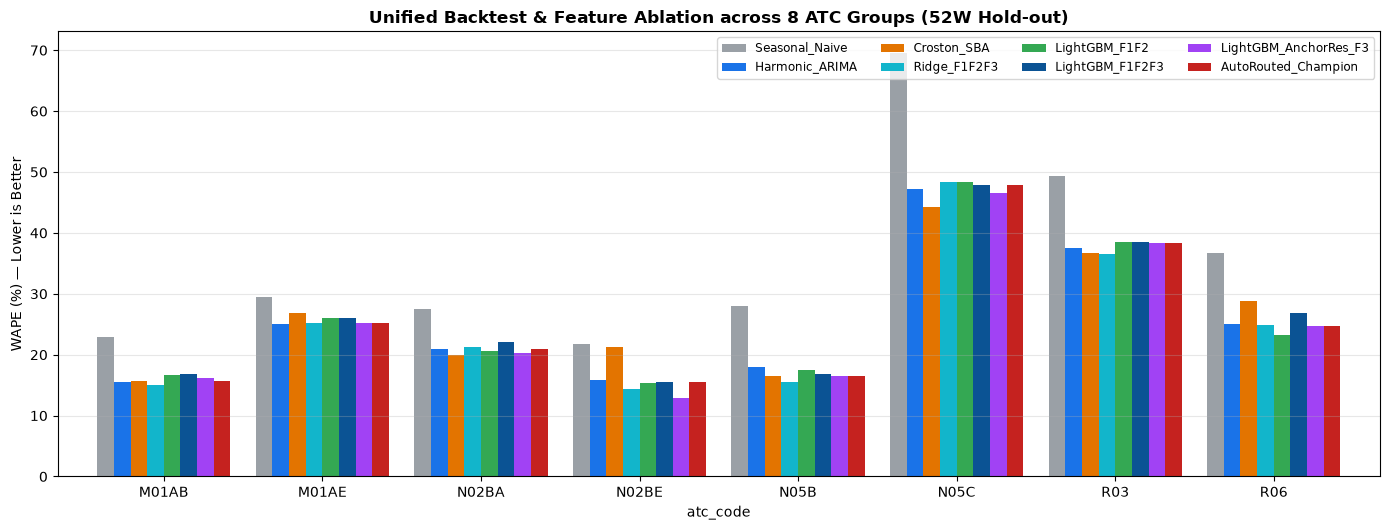

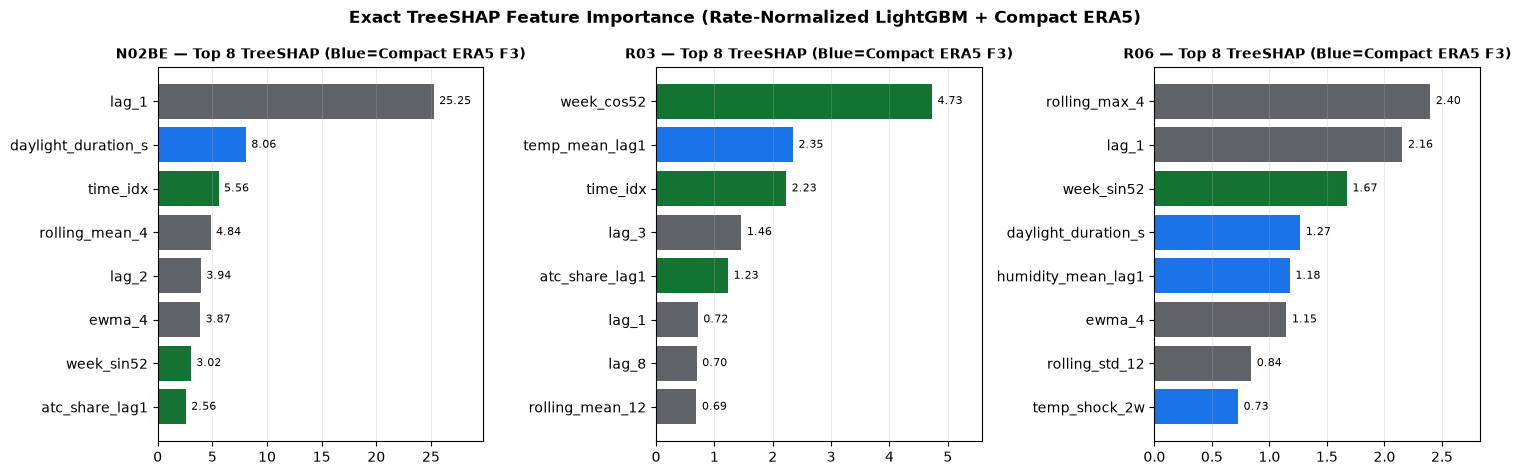

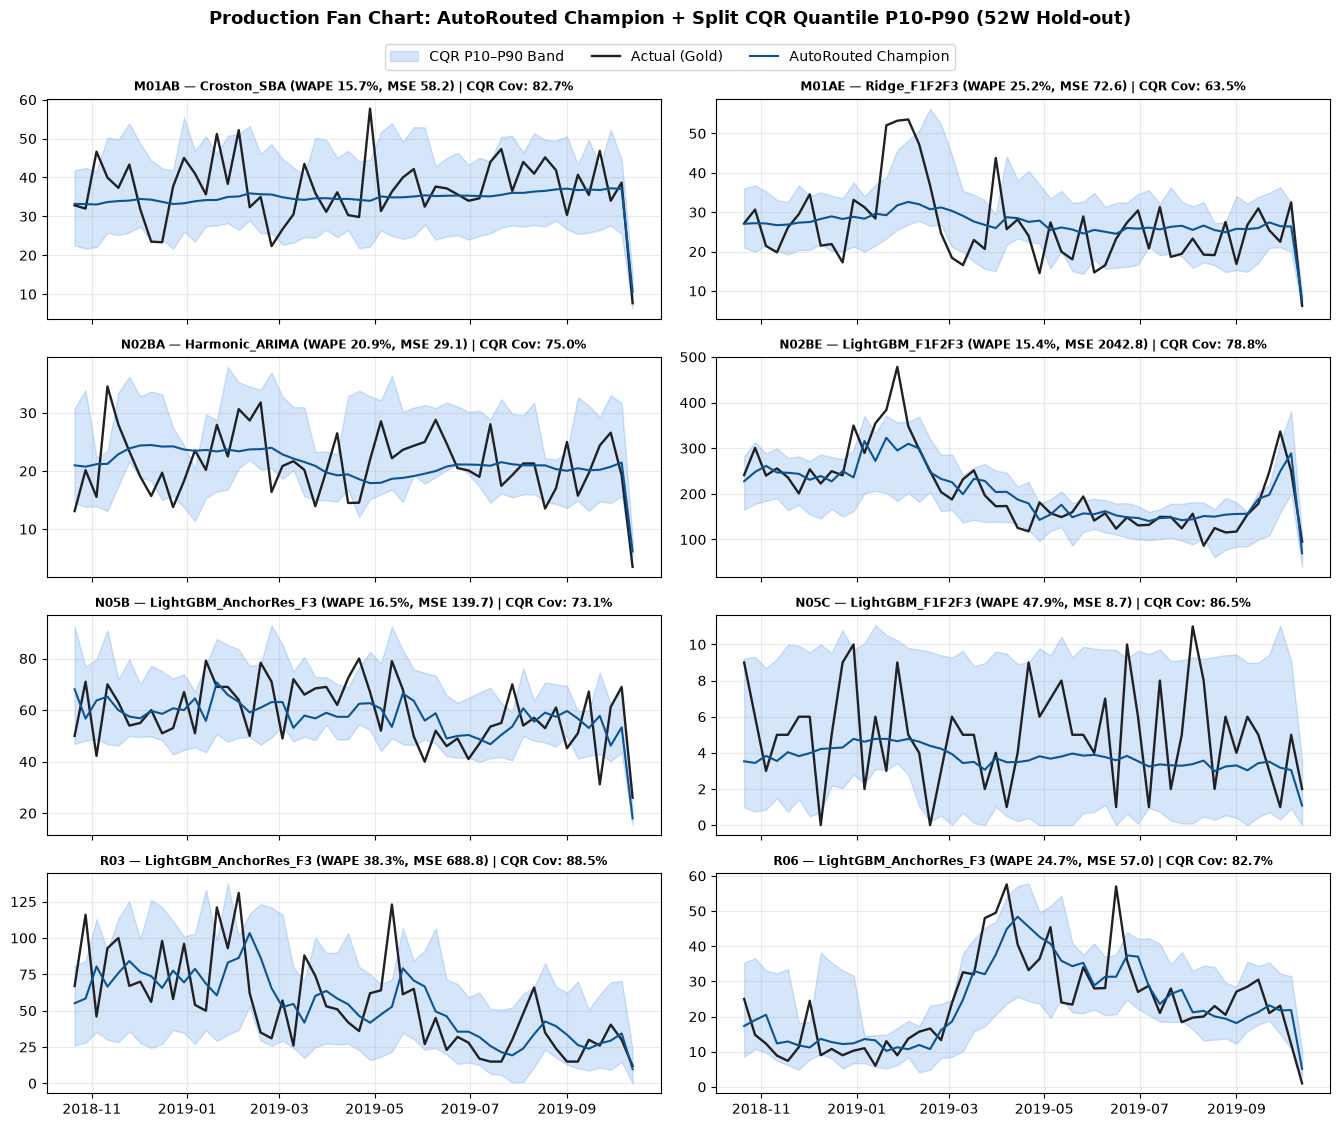

Saved all unified CSVs, PNGs, and model_card.json!


In [5]:
# 4. Xuất 3 biểu đồ 300 DPI: Ablation, TreeSHAP, CQR Fan Chart & lưu model_card.json
plot_m = ["Seasonal_Naive", "Harmonic_ARIMA", "Croston_SBA", "Ridge_F1F2F3", "LightGBM_F1F2", "LightGBM_F1F2F3", "LightGBM_AnchorRes_F3", "AutoRouted_Champion"]
ax = piv_wape[plot_m].plot(kind="bar", figsize=(14, 5.4), width=0.84, color=["#9AA0A6", "#1A73E8", "#E37400", "#12B5CB", "#34A853", "#0B5394", "#A142F4", "#C5221F"])
ax.set_ylabel("WAPE (%) — Lower is Better")
ax.set_title("Unified Backtest & Feature Ablation across 8 ATC Groups (52W Hold-out)", fontweight="bold")
ax.legend(ncol=4, loc="upper right", fontsize=8.5)
ax.grid(axis="y", alpha=0.3)
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(ART_DIR / "eval_ablation_wape.png", dpi=300, bbox_inches="tight")
plt.show()

f_cols_shap = catalog["weekly_compact_feature_cols"]
f3_set, f2_set = set(catalog["f3_compact_cols"]), set(catalog["f2_cols"])
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
for ax, atc in zip(axes, ["N02BE", "R03", "R06"]):
    sub = df_shap[df_shap["atc_code"] == atc]
    mean_abs = sub[f_cols_shap].abs().mean().sort_values(ascending=False).head(8)[::-1]
    bcol = ["#1A73E8" if c in f3_set else ("#137333" if c in f2_set else "#5F6368") for c in mean_abs.index]
    bars = ax.barh(mean_abs.index, mean_abs.values, color=bcol)
    for b, val in zip(bars, mean_abs.values):
        ax.text(val + max(mean_abs.values) * 0.02, b.get_y() + b.get_height() / 2, f"{val:.2f}", va="center", fontsize=8)
    ax.set_xlim(0, max(mean_abs.values) * 1.18)
    ax.set_title(f"{atc} — Top 8 TreeSHAP (Blue=Compact ERA5 F3)", fontsize=10, fontweight="bold")
    ax.grid(axis="x", alpha=0.25)
fig.suptitle("Exact TreeSHAP Feature Importance (Rate-Normalized LightGBM + Compact ERA5)", fontsize=12.5, fontweight="bold")
fig.tight_layout()
fig.savefig(ART_DIR / "eval_treeshap_summary.png", dpi=300, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(4, 2, figsize=(13.5, 11), sharex=True)
for ax, atc in zip(axes.flat, sorted(df_quant["atc_code"].unique())):
    qg = df_quant[df_quant["atc_code"] == atc].sort_values("week_end")
    pg = df_holdout[(df_holdout["atc_code"] == atc) & (df_holdout["model_name"] == "AutoRouted_Champion")].sort_values("week_end")
    sel_m = pg["feature_set"].iloc[0].split("|")[0].replace("selected=", "")
    wape_r = piv_wape.loc[atc, "AutoRouted_Champion"]
    mse_r = piv_mse.loc[atc, "AutoRouted_Champion"]
    ax.fill_between(qg["week_end"], qg["q10"], qg["q90"], color="#1A73E8", alpha=0.18, label="CQR P10–P90 Band")
    ax.plot(qg["week_end"], qg["y_true"], color="#202124", lw=1.7, label="Actual (Gold)")
    ax.plot(pg["week_end"], pg["y_pred"], color="#0B5394", lw=1.5, label="AutoRouted Champion")
    cov = df_qcov.loc[df_qcov["atc_code"] == atc, "cov_80_cqr_pct"].iloc[0]
    ax.set_title(f"{atc} — {sel_m} (WAPE {wape_r:.1f}%, MSE {mse_r:.1f}) | CQR Cov: {cov:.1f}%", fontsize=8.8, fontweight="bold")
    ax.grid(alpha=0.25)
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=3, bbox_to_anchor=(0.5, 0.995))
fig.suptitle("Production Fan Chart: AutoRouted Champion + Split CQR Quantile P10-P90 (52W Hold-out)", fontsize=13, fontweight="bold", y=1.02)
fig.tight_layout()
fig.savefig(ART_DIR / "eval_fanchart_52w.png", dpi=300, bbox_inches="tight")
plt.show()

shap_top = {}
for atc in sorted(df_shap["atc_code"].unique()):
    sub = df_shap[df_shap["atc_code"] == atc]
    s_top = sub[f_cols_shap].abs().mean().sort_values(ascending=False).head(5)
    f3_share = 100.0 * float(sub[list(f3_set)].abs().sum().sum()) / float(sub[f_cols_shap].abs().sum().sum())
    shap_top[atc] = {"top5": {k: round(float(v), 3) for k, v in s_top.items()}, "f3_weather_shap_share_pct": round(f3_share, 1)}

card = {
    "pipeline": "Unified 5-Notebook PharmaFlow Demand Forecasting",
    "scope": "DATA -> FORECAST (Prediction Quality only; OBSERVED data)",
    "total_training_elapsed_sec": train_summary["total_elapsed_seconds"],
    "speedup_vs_paper2024": round((54 * 3600) / train_summary["total_elapsed_seconds"], 1),
    "leakage_checks": catalog["leakage_tests"],
    "autorouted_champions": routed_df[["atc_code", "feature_set", "WAPE_pct", "MASE", "MSE", "Bias_pct"]].to_dict("records"),
    "lowest_mse_by_atc": winners_oracle[["atc_code", "model_name", "MSE", "WAPE_pct", "MASE"]].to_dict("records"),
    "cqr_coverage_raw_mean_pct": round(float(df_qcov["cov_80_raw_pct"].mean()), 1),
    "cqr_coverage_calibrated_mean_pct": round(float(df_qcov["cov_80_cqr_pct"].mean()), 1),
    "shap_weather_share_by_atc": shap_top,
}
(ART_DIR / "model_card.json").write_text(json.dumps(card, indent=2, ensure_ascii=False), encoding="utf-8")
print("Saved all unified CSVs, PNGs, and model_card.json!")